# Kernel-safe revision

This revision fixes the likely kernel-kill causes: unclosed PIL files in DataLoader workers, persistent worker/prefetch pressure, GPU-resident deep-copied checkpoints, allocation of a second full model before releasing the first, DataParallel overhead, and large repeated notebook progress output. The default uses one T4 for stability because this dataset and both architectures fit comfortably on one T4.


In [1]:
# Cell 1: Install packages
!pip install -q imagehash captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 11.8 MB/s eta 0:00:0000:01


In [2]:
# Cell 2: Imports and configuration (memory-safe, no workers)
import os
import re
import gc
import json
import time
import copy
import random
import hashlib
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import imagehash

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    matthews_corrcoef
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import (
    MobileNet_V3_Large_Weights,
    ResNet50_Weights
)

from captum.attr import LayerGradCam, LayerAttribution

warnings.filterwarnings("ignore")

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 64          # stable on one T4 at 224px
NUM_WORKERS = 2          # conservative Kaggle RAM/worker setting
PERSISTENT_WORKERS = False  # prevents worker/process memory surviving between loaders
PREFETCH_FACTOR = 2 if NUM_WORKERS > 0 else None
FINAL_EPOCHS = 15
TEST_EPOCHS = 12
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 5

OUTPUT_DIR = Path("/kaggle/working/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
USE_DATA_PARALLEL = False  # nn.DataParallel was slow/unstable here; one T4 is sufficient

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything(SEED)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(i, torch.cuda.get_device_name(i))

PyTorch: 2.10.0+cu128
Device: cuda:0
GPU count: 2
0 Tesla T4
1 Tesla T4


In [ ]:
# Cell 3: Find only the attached MLC-BD images

from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")
VALID_EXTENSIONS = {".png", ".jpg", ".jpeg", ".webp"}

print("Attached Kaggle inputs:")
if INPUT_ROOT.exists():
    for item in INPUT_ROOT.iterdir():
        print(" -", item)
else:
    raise RuntimeError("/kaggle/input does not exist.")

all_images = [
    path
    for path in INPUT_ROOT.rglob("*")
    if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
]

print("\nTotal images found:", len(all_images))

if len(all_images) == 0:
    raise RuntimeError(
        "No images were found. Click Add Input in Kaggle, "
        "attach the MLC-BD dataset, restart the session, "
        "and run the notebook again."
    )

print("\nFirst 10 image paths:")
for path in all_images[:10]:
    print(path)

Attached Kaggle inputs:
 - /kaggle/input/datasets

Total images found: 10683

First 10 image paths:
/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD Multi-Platform Land Cover Imagery Dataset o/MLC-BD/MLC-BD/ArcGIS Map/Trees_Forests/ArcGIS_Trees_Forests_0457.png
/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD Multi-Platform Land Cover Imagery Dataset o/MLC-BD/MLC-BD/ArcGIS Map/Trees_Forests/ArcGIS_Trees_Forests_0418.png
/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD Multi-Platform Land Cover Imagery Dataset o/MLC-BD/MLC-BD/ArcGIS Map/Trees_Forests/ArcGIS_Trees_Forests_0475.png
/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD Multi-Platform Land Cover Imagery Dataset o/MLC-BD/MLC-BD/ArcGIS Map/Trees_Forests/ArcGIS_Trees_Forests_0358.png
/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD Multi-Platform Land Cover Imagery Dataset o/MLC-BD/MLC-BD/ArcGIS Map/Trees_Forests/ArcGIS_Trees_Forests_0174.png
/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD Multi-Platform Land Cover Imagery Dataset o/MLC-BD/MLC-BD/A

In [4]:
# Cell 4: Build MLC-BD metadata from folder names

import pandas as pd
import re

SOURCE_MAP = {
    "arcgis": "ArcGIS",
    "arcgis map": "ArcGIS",
    "bing": "Bing",
    "bing map": "Bing",
    "bing maps": "Bing",
    "google": "Google",
    "google map": "Google",
    "google maps": "Google",
}

CLASS_MAP = {
    "agricultural land": "Agricultural Land",
    "beaches coastline": "Beaches/Coastline",
    "beach coastline": "Beaches/Coastline",
    "built up areas": "Built-up Areas",
    "built up area": "Built-up Areas",
    "grasslands open land": "Grasslands/Open Land",
    "grassland open land": "Grasslands/Open Land",
    "hills mountains": "Hills/Mountains",
    "hill mountains": "Hills/Mountains",
    "trees forests": "Trees/Forests",
    "tree forests": "Trees/Forests",
    "water bodies": "Water Bodies",
    "water body": "Water Bodies",
}


def normalize_folder_name(name):
    """Turn Trees_Forests or Built-up_Areas into plain lowercase words."""
    name = str(name).lower()
    name = re.sub(r"[_\-]+", " ", name)
    name = re.sub(r"[^a-z0-9 ]", " ", name)
    name = re.sub(r"\s+", " ", name)
    return name.strip()


def identify_source(path):
    for part in path.parts:
        normalized = normalize_folder_name(part)

        if normalized in SOURCE_MAP:
            return SOURCE_MAP[normalized]

        if normalized.startswith("arcgis"):
            return "ArcGIS"

        if normalized.startswith("bing"):
            return "Bing"

        if normalized.startswith("google"):
            return "Google"

    return None


def identify_class(path):
    for part in path.parts:
        normalized = normalize_folder_name(part)

        if normalized in CLASS_MAP:
            return CLASS_MAP[normalized]

    return None


rows = []
unmatched = []

for path in all_images:
    source = identify_source(path)
    label = identify_class(path)

    if source is not None and label is not None:
        rows.append({
            "path": str(path),
            "source": source,
            "label": label,
        })
    else:
        unmatched.append({
            "path": str(path),
            "source_found": source,
            "label_found": label,
        })


# Columns are explicitly provided, so an empty result cannot cause KeyError.
meta = pd.DataFrame(
    rows,
    columns=["path", "source", "label"]
)

meta = (
    meta
    .drop_duplicates(subset="path")
    .reset_index(drop=True)
)

unmatched_df = pd.DataFrame(unmatched)

print("Images examined:", len(all_images))
print("Usable images:", len(meta))
print("Unmatched images:", len(unmatched_df))
print("Missing from expected total:", 10683 - len(meta))


# Stop with useful diagnostic information instead of a KeyError.
if meta.empty:
    print("\nThe first 10 paths found were:")

    for path in all_images[:10]:
        print(path)
        print("Folder parts:", path.parts)
        print()

    raise RuntimeError(
        "No MLC-BD paths matched the expected source and class folders. "
        "Examine the paths printed above."
    )


if not unmatched_df.empty:
    print("\nFirst unmatched paths:")
    display(unmatched_df.head(20))

    unmatched_df.to_csv(
        OUTPUT_DIR / "unmatched_paths.csv",
        index=False
    )


display(meta.head())

distribution_table = pd.crosstab(
    index=meta["label"],
    columns=meta["source"],
    margins=True
)

display(distribution_table)

meta.to_csv(
    OUTPUT_DIR / "metadata_initial.csv",
    index=False
)

print("\nMetadata saved successfully.")

Images examined: 10683
Usable images: 10683
Unmatched images: 0
Missing from expected total: 0


,path,source,label
0,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,ArcGIS,Trees/Forests
1,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,ArcGIS,Trees/Forests
2,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,ArcGIS,Trees/Forests
3,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,ArcGIS,Trees/Forests
4,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,ArcGIS,Trees/Forests


source,ArcGIS,Bing,Google,All
label,,,,
Agricultural Land,506,525,516,1547
Beaches/Coastline,515,517,506,1538
Built-up Areas,505,515,500,1520
Grasslands/Open Land,504,505,500,1509
Hills/Mountains,519,545,456,1520
Trees/Forests,503,506,517,1526
Water Bodies,504,519,500,1523
All,3556,3632,3495,10683



Metadata saved successfully.


In [5]:
# Cell 5: Display random dataset examples
classes = sorted(meta["label"].unique())
sources = sorted(meta["source"].unique())

fig, axes = plt.subplots(len(classes), len(sources), figsize=(12, 20))

for r, label in enumerate(classes):
    for c, source in enumerate(sources):
        subset = meta[(meta.label == label) & (meta.source == source)]
        ax = axes[r, c]
        ax.axis("off")
        if len(subset):
            row = subset.sample(1, random_state=SEED + r + c).iloc[0]
            img = Image.open(row.path).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"{label}\n{source}", fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dataset_examples.png", dpi=200, bbox_inches="tight")
plt.show()

[Image output removed. It showed basemap imagery from Google, Bing or ArcGIS, which is not redistributed in this repository.]


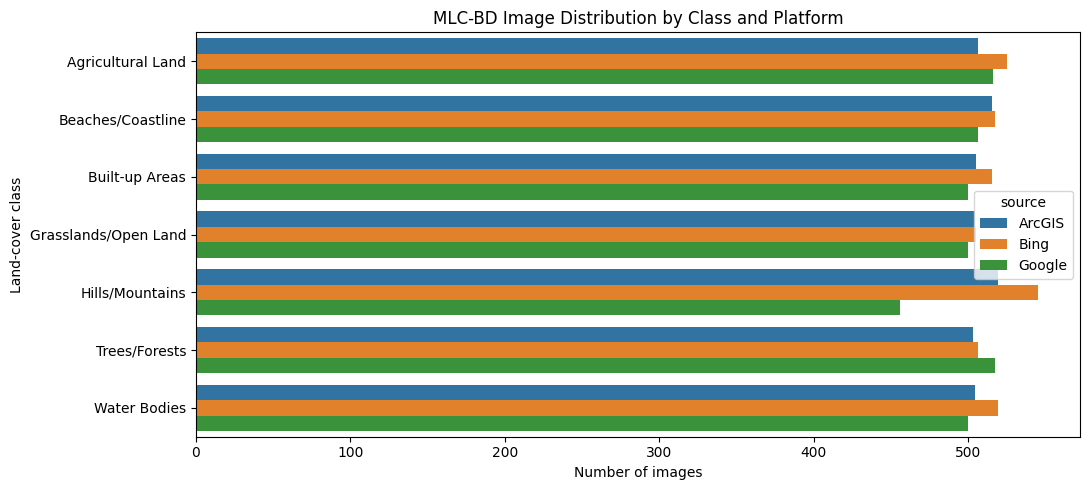

In [6]:
# Cell 6: Plot dataset distribution
plt.figure(figsize=(11, 5))
sns.countplot(data=meta, y="label", hue="source", order=classes)
plt.title("MLC-BD Image Distribution by Class and Platform")
plt.xlabel("Number of images")
plt.ylabel("Land-cover class")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "dataset_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
# Cell 7: Exact-duplicate audit
def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

meta["sha256"] = [sha256_file(p) for p in meta["path"]]
exact_groups = meta[meta.duplicated("sha256", keep=False)].sort_values("sha256")

print("Images belonging to exact-duplicate groups:", len(exact_groups))
print("Unique duplicate hashes:", exact_groups["sha256"].nunique())
display(exact_groups.head(20))
exact_groups.to_csv(OUTPUT_DIR / "exact_duplicate_groups.csv", index=False)

Images belonging to exact-duplicate groups: 16
Unique duplicate hashes: 8


,path,source,label,sha256
8080,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,056d2c163cda14cecef83674bf34d13efbf6bb1216c757...
8104,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,056d2c163cda14cecef83674bf34d13efbf6bb1216c757...
7826,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,3845cb01b5e76d167e73dcc30b62d11ce77b64ded70970...
8038,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,3845cb01b5e76d167e73dcc30b62d11ce77b64ded70970...
7794,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,66854188cc6295a8a51cb228b00b16794d62e1cde4160d...
8165,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,66854188cc6295a8a51cb228b00b16794d62e1cde4160d...
7781,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,8bf641d15b16e97781aa27c9127194203f1e527d003188...
8178,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,8bf641d15b16e97781aa27c9127194203f1e527d003188...
7901,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,a5c79f8d54f2b50012011693d2ea5956172a5addcfc0fe...
8152,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,Agricultural Land,a5c79f8d54f2b50012011693d2ea5956172a5addcfc0fe...


In [8]:
# Cell 8: Remove exact duplicates safely
clean_meta = meta.drop_duplicates("sha256", keep="first").copy().reset_index(drop=True)
print("Before exact duplicate removal:", len(meta))
print("After exact duplicate removal:", len(clean_meta))

clean_meta.to_csv(OUTPUT_DIR / "metadata_exact_deduplicated.csv", index=False)

Before exact duplicate removal: 10683
After exact duplicate removal: 10675


In [9]:
# Cell 9: Perceptual-hash audit
def compute_phash(path):
    try:
        with Image.open(path) as img:
            return str(imagehash.phash(img.convert("RGB").resize((256, 256))))
    except Exception:
        return None

clean_meta["phash"] = [compute_phash(p) for p in clean_meta["path"]]
phash_groups = clean_meta[
    clean_meta["phash"].notna() & clean_meta.duplicated("phash", keep=False)
].sort_values("phash")

print("Images in identical perceptual-hash groups:", len(phash_groups))
display(phash_groups.head(20))
phash_groups.to_csv(OUTPUT_DIR / "perceptual_hash_groups.csv", index=False)
clean_meta.to_csv(OUTPUT_DIR / "metadata_audited.csv", index=False)

Images in identical perceptual-hash groups: 0


,path,source,label,sha256,phash


In [10]:
# Cell 10: Create class mapping
CLASS_NAMES = sorted(clean_meta["label"].unique())
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
IDX_TO_CLASS = {i: name for name, i in CLASS_TO_IDX.items()}

clean_meta["target"] = clean_meta["label"].map(CLASS_TO_IDX)

print(CLASS_TO_IDX)
with open(OUTPUT_DIR / "class_mapping.json", "w") as f:
    json.dump(CLASS_TO_IDX, f, indent=2)

{'Agricultural Land': 0, 'Beaches/Coastline': 1, 'Built-up Areas': 2, 'Grasslands/Open Land': 3, 'Hills/Mountains': 4, 'Trees/Forests': 5, 'Water Bodies': 6}


In [11]:
# Cell 11: Define split functions
def create_mixed_split(df, seed=42):
    strat = df["label"].astype(str) + "__" + df["source"].astype(str)
    train_df, temp_df = train_test_split(
        df, test_size=0.30, random_state=seed, stratify=strat
    )
    temp_strat = temp_df["label"].astype(str) + "__" + temp_df["source"].astype(str)
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=seed, stratify=temp_strat
    )
    return train_df.copy(), val_df.copy(), test_df.copy()

def create_heldout_split(df, heldout_source, seed=42):
    source_train = df[df["source"] != heldout_source].copy()
    test_df = df[df["source"] == heldout_source].copy()

    strat = source_train["label"].astype(str) + "__" + source_train["source"].astype(str)
    train_df, val_df = train_test_split(
        source_train,
        test_size=0.15,
        random_state=seed,
        stratify=strat
    )
    return train_df.copy(), val_df.copy(), test_df.copy()

mixed_train, mixed_val, mixed_test = create_mixed_split(clean_meta, SEED)

print(len(mixed_train), len(mixed_val), len(mixed_test))
print("Mixed test sources:", mixed_test["source"].value_counts().to_dict())

7472 1601 1602
Mixed test sources: {'Bing': 546, 'ArcGIS': 533, 'Google': 523}


In [12]:
# Cell 12: Save every split
split_folder = OUTPUT_DIR / "splits"
split_folder.mkdir(exist_ok=True)

mixed_train.to_csv(split_folder / "mixed_train.csv", index=False)
mixed_val.to_csv(split_folder / "mixed_val.csv", index=False)
mixed_test.to_csv(split_folder / "mixed_test.csv", index=False)

for source in ["ArcGIS", "Bing", "Google"]:
    tr, va, te = create_heldout_split(clean_meta, source, SEED)
    tr.to_csv(split_folder / f"heldout_{source}_train.csv", index=False)
    va.to_csv(split_folder / f"heldout_{source}_val.csv", index=False)
    te.to_csv(split_folder / f"heldout_{source}_test.csv", index=False)
    print(source, len(tr), len(va), len(te), te.source.unique())

ArcGIS 6051 1068 3556 ['ArcGIS']
Bing 5986 1057 3632 ['Bing']
Google 6109 1079 3487 ['Google']


In [13]:
# Cell 12b: Verify splits
import pandas as pd
from pathlib import Path

split_folder = OUTPUT_DIR / "splits"

# Load mixed splits
mixed_train = pd.read_csv(split_folder / "mixed_train.csv")
mixed_val = pd.read_csv(split_folder / "mixed_val.csv")
mixed_test = pd.read_csv(split_folder / "mixed_test.csv")

print("Mixed split sizes:", len(mixed_train), len(mixed_val), len(mixed_test))
print("\nMixed train class/source distribution:")
print(pd.crosstab(mixed_train["label"], mixed_train["source"]))
print("\nMixed val class/source distribution:")
print(pd.crosstab(mixed_val["label"], mixed_val["source"]))
print("\nMixed test class/source distribution:")
print(pd.crosstab(mixed_test["label"], mixed_test["source"]))

# Check path overlap between splits
all_mixed_paths = set(mixed_train["path"]) | set(mixed_val["path"]) | set(mixed_test["path"])
print("\nMixed splits unique paths:", len(all_mixed_paths), "out of total", len(mixed_train)+len(mixed_val)+len(mixed_test))
print("Any overlap between splits?",
      bool(set(mixed_train["path"]) & set(mixed_val["path"]) or
           set(mixed_train["path"]) & set(mixed_test["path"]) or
           set(mixed_val["path"]) & set(mixed_test["path"])))

# Verify heldout splits
for source in ["ArcGIS", "Bing", "Google"]:
    tr = pd.read_csv(split_folder / f"heldout_{source}_train.csv")
    va = pd.read_csv(split_folder / f"heldout_{source}_val.csv")
    te = pd.read_csv(split_folder / f"heldout_{source}_test.csv")

    print(f"\n--- Heldout {source} ---")
    print("Sizes:", len(tr), len(va), len(te))
    print("Test sources present:", te["source"].unique())
    print("Train sources present:", tr["source"].unique())
    print("Val sources present:", va["source"].unique())
    print("Test class distribution:")
    print(te["label"].value_counts())
    print("Train class distribution (first 3):")
    print(tr["label"].value_counts().head(3))

    # Check no heldout source in train/val
    assert source not in tr["source"].unique(), f"Leakage: {source} found in train"
    assert source not in va["source"].unique(), f"Leakage: {source} found in val"
    print("No leakage: heldout source not in train/val.")

Mixed split sizes: 7472 1601 1602

Mixed train class/source distribution:
source                ArcGIS  Bing  Google
label                                     
Agricultural Land        354   367     356
Beaches/Coastline        361   362     354
Built-up Areas           354   360     350
Grasslands/Open Land     353   354     350
Hills/Mountains          363   381     319
Trees/Forests            352   354     362
Water Bodies             353   363     350

Mixed val class/source distribution:
source                ArcGIS  Bing  Google
label                                     
Agricultural Land         76    79      76
Beaches/Coastline         77    77      76
Built-up Areas            75    77      75
Grasslands/Open Land      76    76      75
Hills/Mountains           78    82      69
Trees/Forests             76    76      77
Water Bodies              75    78      75

Mixed test class/source distribution:
source                ArcGIS  Bing  Google
label                           

In [14]:
# Cell 13: Define transforms
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

standard_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.80, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

strong_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.20, hue=0.05),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3)], p=0.20),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [15]:
# Cell 14: Dataset and DataLoader (kernel-safe)
class LandCoverDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.paths = dataframe["path"].tolist()
        self.targets = dataframe["target"].astype(int).tolist()
        self.sources = dataframe["source"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        # Context manager closes every image file immediately. This prevents
        # file-descriptor and worker-memory leakage during long training runs.
        with Image.open(path) as img:
            image = img.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, self.targets[idx], path, self.sources[idx]

def make_loaders(train_df, val_df, test_df, train_transform, batch_size=BATCH_SIZE):
    datasets = (
        LandCoverDataset(train_df, train_transform),
        LandCoverDataset(val_df, eval_transform),
        LandCoverDataset(test_df, eval_transform),
    )
    common = dict(
        batch_size=batch_size,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=False,
    )
    if NUM_WORKERS > 0:
        common["prefetch_factor"] = PREFETCH_FACTOR

    train_loader = DataLoader(datasets[0], shuffle=True, drop_last=False, **common)
    val_loader = DataLoader(datasets[1], shuffle=False, drop_last=False, **common)
    test_loader = DataLoader(datasets[2], shuffle=False, drop_last=False, **common)
    return train_loader, val_loader, test_loader


In [16]:
# Cell 15: Build MobileNetV3 or ResNet-50 (stable single-GPU mode)
def build_model(model_name, num_classes):
    if model_name == "mobilenet_v3_large":
        model = models.mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    elif model_name == "resnet50":
        model = models.resnet50(weights=ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    else:
        raise ValueError(f"Unknown model: {model_name}")

    model = model.to(DEVICE)
    if USE_DATA_PARALLEL and torch.cuda.device_count() > 1:
        model = nn.DataParallel(model)
    return model

def base_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


In [17]:
# Cell 16: Metrics helper
def compute_metrics(y_true, y_pred):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
        "mcc": matthews_corrcoef(y_true, y_pred),
    }

In [18]:
# Cell 17: One epoch with AMP and bounded memory
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    running_loss = 0.0
    y_true, y_pred = [], []

    for images, targets, _, _ in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                logits = model(images)
                loss = criterion(logits, targets)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        running_loss += float(loss.detach()) * targets.size(0)
        preds = logits.detach().argmax(1)
        y_true.extend(targets.cpu().tolist())
        y_pred.extend(preds.cpu().tolist())
        del images, targets, logits, loss, preds

    metrics = compute_metrics(y_true, y_pred)
    metrics["loss"] = running_loss / len(loader.dataset)
    return metrics


In [19]:
# Cell 18: Full training function (no GPU checkpoint duplication)
def train_experiment(experiment_name, model_name, train_df, val_df, test_df,
                     train_transform, epochs=15):
    seed_everything(SEED)
    exp_dir = OUTPUT_DIR / experiment_name
    exp_dir.mkdir(parents=True, exist_ok=True)
    train_loader = val_loader = test_loader = model = optimizer = None

    try:
        train_loader, val_loader, test_loader = make_loaders(
            train_df, val_df, test_df, train_transform
        )
        model = build_model(model_name, len(CLASS_NAMES))
        criterion = nn.CrossEntropyLoss()
        optimizer = torch.optim.AdamW(
            model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", patience=2, factor=0.5
        )
        scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

        history, best_state = [], None
        best_val_f1, stale = -1.0, 0
        start = time.time()

        for epoch in range(1, epochs + 1):
            train_metrics = run_epoch(model, train_loader, criterion, optimizer, scaler)
            val_metrics = run_epoch(model, val_loader, criterion)
            scheduler.step(val_metrics["macro_f1"])

            history.append({
                "epoch": epoch,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{f"val_{k}": v for k, v in val_metrics.items()},
                "learning_rate": optimizer.param_groups[0]["lr"],
            })
            print(f"{experiment_name} | {epoch:02d}/{epochs} | "
                  f"train F1={train_metrics['macro_f1']:.4f} | "
                  f"val F1={val_metrics['macro_f1']:.4f}")

            if val_metrics["macro_f1"] > best_val_f1:
                best_val_f1 = val_metrics["macro_f1"]
                # Critical fix: checkpoint tensors are copied to CPU, not duplicated on GPU.
                best_state = {k: v.detach().cpu().clone()
                              for k, v in base_model(model).state_dict().items()}
                torch.save(best_state, exp_dir / "best_model.pth")
                stale = 0
            else:
                stale += 1
            if stale >= PATIENCE:
                print("Early stopping.")
                break

        history_df = pd.DataFrame(history)
        history_df.to_csv(exp_dir / "history.csv", index=False)
        plot_history(history_df, exp_dir, experiment_name)

        # Reuse the existing model. Do not allocate a second model while optimizer
        # states and the first model are still on GPU.
        base_model(model).load_state_dict(best_state)
        test_output = evaluate_model(model, test_loader, exp_dir)
        test_output.update({
            "experiment": experiment_name, "model": model_name,
            "best_val_macro_f1": best_val_f1,
            "training_minutes": (time.time() - start) / 60,
            "epochs_completed": len(history_df),
        })
        with open(exp_dir / "summary.json", "w") as f:
            json.dump(test_output, f, indent=2)
        return test_output

    finally:
        del train_loader, val_loader, test_loader, model, optimizer
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()


In [20]:
# Cell 19: Evaluation and saved predictions
def evaluate_model(model, loader, exp_dir):
    model.eval()
    all_true, all_pred, all_prob, all_paths, all_sources = [], [], [], [], []

    start = time.time()
    with torch.no_grad():
        for images, targets, paths, sources_batch in loader:
            images = images.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
                logits = model(images)
                probs = torch.softmax(logits, dim=1)

            preds = probs.argmax(dim=1).cpu().numpy()
            all_true.extend(targets.numpy())
            all_pred.extend(preds)
            all_prob.extend(probs.cpu().numpy())
            all_paths.extend(paths)
            all_sources.extend(sources_batch)

    inference_seconds = time.time() - start
    metrics = compute_metrics(all_true, all_pred)
    metrics["inference_seconds"] = inference_seconds
    metrics["milliseconds_per_image"] = 1000 * inference_seconds / len(all_true)

    report = classification_report(
        all_true,
        all_pred,
        target_names=CLASS_NAMES,
        zero_division=0,
        output_dict=True
    )
    pd.DataFrame(report).T.to_csv(exp_dir / "classification_report.csv")

    cm = confusion_matrix(all_true, all_pred)
    np.save(exp_dir / "confusion_matrix.npy", cm)
    plot_confusion_matrix(cm, exp_dir)

    probabilities = np.asarray(all_prob)
    pred_df = pd.DataFrame({
        "path": all_paths,
        "source": all_sources,
        "true_idx": all_true,
        "pred_idx": all_pred,
        "true_label": [IDX_TO_CLASS[i] for i in all_true],
        "pred_label": [IDX_TO_CLASS[i] for i in all_pred],
        "confidence": probabilities.max(axis=1),
        "correct": np.asarray(all_true) == np.asarray(all_pred),
    })
    for i, class_name in enumerate(CLASS_NAMES):
        pred_df[f"prob_{class_name}"] = probabilities[:, i]
    pred_df.to_csv(exp_dir / "predictions.csv", index=False)

    return metrics

def plot_confusion_matrix(cm, exp_dir):
    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
    )
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title("Confusion Matrix")
    plt.xticks(rotation=40, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(exp_dir / "confusion_matrix.png", dpi=220, bbox_inches="tight")
    plt.close()

def plot_history(history_df, exp_dir, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history_df.epoch, history_df.train_loss, label="Train")
    axes[0].plot(history_df.epoch, history_df.val_loss, label="Validation")
    axes[0].set_title("Loss Curve")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history_df.epoch, history_df.train_macro_f1, label="Train")
    axes[1].plot(history_df.epoch, history_df.val_macro_f1, label="Validation")
    axes[1].set_title("Macro-F1 Curve")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Macro-F1")
    axes[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(exp_dir / "learning_curves.png", dpi=220, bbox_inches="tight")
    plt.close()

In [ ]:
# Cell 20: Fast two-epoch smoke test
SMOKE_TRAIN_N = min(300, len(mixed_train))
SMOKE_VAL_N = min(80, len(mixed_val))
SMOKE_TEST_N = min(80, len(mixed_test))
smoke_train = mixed_train.sample(SMOKE_TRAIN_N, random_state=SEED)
smoke_val = mixed_val.sample(SMOKE_VAL_N, random_state=SEED)
smoke_test = mixed_test.sample(SMOKE_TEST_N, random_state=SEED)

print(f"Smoke sizes: {len(smoke_train)}, {len(smoke_val)}, {len(smoke_test)}")
smoke = train_experiment(
    "smoke_test_mobilenet", "mobilenet_v3_large",
    smoke_train, smoke_val, smoke_test,
    standard_train_transform, epochs=2
)
print(smoke)


Smoke sizes: 300, 80, 80
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 188MB/s]


In [22]:
# Cell 21: Mixed baselines, executed sequentially
all_results = []
for model_name in ["mobilenet_v3_large", "resnet50"]:
    print(f"\n===== Starting {model_name} =====")
    result = train_experiment(
        f"mixed_{model_name}", model_name,
        mixed_train, mixed_val, mixed_test,
        standard_train_transform, epochs=FINAL_EPOCHS
    )
    all_results.append(result)
    pd.DataFrame(all_results).to_csv(OUTPUT_DIR / "mixed_results_partial.csv", index=False)
    print(result)
    gc.collect()
    torch.cuda.empty_cache()

mixed_results = pd.DataFrame(all_results).sort_values("macro_f1", ascending=False)
mixed_results.to_csv(OUTPUT_DIR / "mixed_results.csv", index=False)
display(mixed_results)


mixed_mobilenet_v3_large | 01/15 | train F1=0.8530 | val F1=0.9346
mixed_mobilenet_v3_large | 02/15 | train F1=0.9632 | val F1=0.9639
mixed_mobilenet_v3_large | 03/15 | train F1=0.9731 | val F1=0.9807
mixed_mobilenet_v3_large | 04/15 | train F1=0.9798 | val F1=0.9850
mixed_mobilenet_v3_large | 05/15 | train F1=0.9842 | val F1=0.9899
mixed_mobilenet_v3_large | 06/15 | train F1=0.9877 | val F1=0.9900
mixed_mobilenet_v3_large | 07/15 | train F1=0.9879 | val F1=0.9875
mixed_mobilenet_v3_large | 08/15 | train F1=0.9879 | val F1=0.9900
mixed_mobilenet_v3_large | 09/15 | train F1=0.9944 | val F1=0.9912
mixed_mobilenet_v3_large | 10/15 | train F1=0.9968 | val F1=0.9944
mixed_mobilenet_v3_large | 11/15 | train F1=0.9946 | val F1=0.9906
mixed_mobilenet_v3_large | 12/15 | train F1=0.9950 | val F1=0.9925
mixed_mobilenet_v3_large | 13/15 | train F1=0.9960 | val F1=0.9900
mixed_mobilenet_v3_large | 14/15 | train F1=0.9975 | val F1=0.9918
mixed_mobilenet_v3_large | 15/15 | train F1=0.9980 | val F1=0.

100%|██████████| 97.8M/97.8M [00:00<00:00, 203MB/s]


mixed_resnet50 | 01/15 | train F1=0.8615 | val F1=0.9743
mixed_resnet50 | 02/15 | train F1=0.9594 | val F1=0.9837
mixed_resnet50 | 03/15 | train F1=0.9760 | val F1=0.9838
mixed_resnet50 | 04/15 | train F1=0.9826 | val F1=0.9794
mixed_resnet50 | 08/15 | train F1=0.9909 | val F1=0.9900
mixed_resnet50 | 09/15 | train F1=0.9902 | val F1=0.9894
mixed_resnet50 | 10/15 | train F1=0.9956 | val F1=0.9950
mixed_resnet50 | 11/15 | train F1=0.9968 | val F1=0.9925
mixed_resnet50 | 12/15 | train F1=0.9969 | val F1=0.9931
mixed_resnet50 | 13/15 | train F1=0.9965 | val F1=0.9944
mixed_resnet50 | 14/15 | train F1=0.9995 | val F1=0.9944
mixed_resnet50 | 15/15 | train F1=0.9980 | val F1=0.9937
Early stopping.
{'accuracy': 0.9912609238451935, 'macro_precision': 0.991326864543646, 'macro_recall': 0.9912052347735443, 'macro_f1': 0.9912353595702605, 'mcc': np.float64(0.9898145342789454), 'inference_seconds': 5.563975095748901, 'milliseconds_per_image': 3.4731430060854565, 'experiment': 'mixed_resnet50', 'mod

,accuracy,macro_precision,macro_recall,macro_f1,mcc,inference_seconds,milliseconds_per_image,experiment,model,best_val_macro_f1,training_minutes,epochs_completed
1,0.991261,0.991327,0.991205,0.991235,0.989815,5.563975,3.473143,mixed_resnet50,resnet50,0.994985,9.945863,15
0,0.989388,0.989421,0.989361,0.989361,0.987629,9.404377,5.870397,mixed_mobilenet_v3_large,mobilenet_v3_large,0.994352,8.369677,15


In [23]:
# Cell 22: Select the winning model (using validation macro-F1 for methodologically sound choice)
BEST_MODEL = mixed_results.sort_values("best_val_macro_f1", ascending=False).iloc[0]["model"]
print("Selected model:", BEST_MODEL)

Selected model: resnet50


In [24]:
# Cell 23: Standard augmentation held-out tests
heldout_standard_results = []

for heldout_source in ["ArcGIS", "Bing", "Google"]:
    print(f"\n===== Held-out {heldout_source} | Standard augmentation =====")
    tr, va, te = create_heldout_split(clean_meta, heldout_source, SEED)
    result = train_experiment(
        experiment_name=f"heldout_{heldout_source}_standard_{BEST_MODEL}",
        model_name=BEST_MODEL,
        train_df=tr,
        val_df=va,
        test_df=te,
        train_transform=standard_train_transform,
        epochs=FINAL_EPOCHS
    )
    result["heldout_source"] = heldout_source
    result["augmentation"] = "standard"
    heldout_standard_results.append(result)
    print(f"----- Finished {heldout_source} standard -----")
    print(json.dumps(result, indent=2))

heldout_standard_df = pd.DataFrame(heldout_standard_results)
display(heldout_standard_df)


===== Held-out ArcGIS | Standard augmentation =====
heldout_ArcGIS_standard_resnet50 | 01/15 | train F1=0.8566 | val F1=0.9699
heldout_ArcGIS_standard_resnet50 | 02/15 | train F1=0.9626 | val F1=0.9632
heldout_ArcGIS_standard_resnet50 | 03/15 | train F1=0.9723 | val F1=0.9859
heldout_ArcGIS_standard_resnet50 | 04/15 | train F1=0.9823 | val F1=0.9708
heldout_ArcGIS_standard_resnet50 | 05/15 | train F1=0.9873 | val F1=0.9840
heldout_ArcGIS_standard_resnet50 | 06/15 | train F1=0.9876 | val F1=0.9841
heldout_ArcGIS_standard_resnet50 | 07/15 | train F1=0.9901 | val F1=0.9887
heldout_ArcGIS_standard_resnet50 | 08/15 | train F1=0.9932 | val F1=0.9897
heldout_ArcGIS_standard_resnet50 | 09/15 | train F1=0.9942 | val F1=0.9887
heldout_ArcGIS_standard_resnet50 | 10/15 | train F1=0.9954 | val F1=0.9916
heldout_ArcGIS_standard_resnet50 | 11/15 | train F1=0.9959 | val F1=0.9840
heldout_ArcGIS_standard_resnet50 | 12/15 | train F1=0.9957 | val F1=0.9878
heldout_ArcGIS_standard_resnet50 | 13/15 | trai

,accuracy,macro_precision,macro_recall,macro_f1,mcc,inference_seconds,milliseconds_per_image,experiment,model,best_val_macro_f1,training_minutes,epochs_completed,heldout_source,augmentation
0,0.746625,0.809762,0.746621,0.715851,0.718157,13.069446,3.675322,heldout_ArcGIS_standard_resnet50,resnet50,0.993439,8.008383,15,ArcGIS,standard
1,0.769273,0.838698,0.773614,0.766861,0.744562,11.206541,3.085501,heldout_Bing_standard_resnet50,resnet50,0.992435,7.380626,14,Bing,standard
2,0.344709,0.586439,0.345576,0.301035,0.286229,11.588871,3.323450,heldout_Google_standard_resnet50,resnet50,0.999060,8.054844,15,Google,standard


In [26]:
# Cell 24: Strong augmentation held-out tests
heldout_strong_results = []

sources_to_test = ["ArcGIS", "Bing", "Google"]
print(f"Running {len(sources_to_test)} held-out experiments with strong augmentation.")
print(f"Estimated time per experiment: ~8-10 minutes (similar to standard runs). Total estimated time: ~25-30 minutes.\n")

for heldout_source in sources_to_test:
    print(f"\n===== Held-out {heldout_source} | Strong augmentation =====")
    tr, va, te = create_heldout_split(clean_meta, heldout_source, SEED)
    result = train_experiment(
        experiment_name=f"heldout_{heldout_source}_strong_{BEST_MODEL}",
        model_name=BEST_MODEL,
        train_df=tr,
        val_df=va,
        test_df=te,
        train_transform=strong_train_transform,
        epochs=FINAL_EPOCHS
    )
    result["heldout_source"] = heldout_source
    result["augmentation"] = "strong"
    heldout_strong_results.append(result)
    print(f"----- Finished {heldout_source} strong -----")
    print(json.dumps(result, indent=2))

heldout_strong_df = pd.DataFrame(heldout_strong_results)
display(heldout_strong_df)

Running 3 held-out experiments with strong augmentation.
Estimated time per experiment: ~8-10 minutes (similar to standard runs). Total estimated time: ~25-30 minutes.


===== Held-out ArcGIS | Strong augmentation =====
heldout_ArcGIS_strong_resnet50 | 01/15 | train F1=0.8373 | val F1=0.9567
heldout_ArcGIS_strong_resnet50 | 02/15 | train F1=0.9490 | val F1=0.9440
heldout_ArcGIS_strong_resnet50 | 03/15 | train F1=0.9624 | val F1=0.9775
heldout_ArcGIS_strong_resnet50 | 04/15 | train F1=0.9696 | val F1=0.9821
heldout_ArcGIS_strong_resnet50 | 05/15 | train F1=0.9768 | val F1=0.9765
heldout_ArcGIS_strong_resnet50 | 06/15 | train F1=0.9805 | val F1=0.9793
heldout_ArcGIS_strong_resnet50 | 07/15 | train F1=0.9833 | val F1=0.9812
heldout_ArcGIS_strong_resnet50 | 08/15 | train F1=0.9864 | val F1=0.9887
heldout_ArcGIS_strong_resnet50 | 09/15 | train F1=0.9881 | val F1=0.9869
heldout_ArcGIS_strong_resnet50 | 10/15 | train F1=0.9897 | val F1=0.9869
heldout_ArcGIS_strong_resnet50 | 11/15 | train F1=

,accuracy,macro_precision,macro_recall,macro_f1,mcc,inference_seconds,milliseconds_per_image,experiment,model,best_val_macro_f1,training_minutes,epochs_completed,heldout_source,augmentation
0,0.794713,0.851769,0.793701,0.777102,0.772575,12.608521,3.545703,heldout_ArcGIS_strong_resnet50,resnet50,0.988730,10.034307,13,ArcGIS,strong
1,0.767621,0.831462,0.771590,0.765563,0.742262,11.160304,3.072771,heldout_Bing_strong_resnet50,resnet50,0.992478,11.746080,15,Bing,strong
2,0.575566,0.731641,0.574747,0.576509,0.542654,10.875511,3.118873,heldout_Google_strong_resnet50,resnet50,0.994424,8.683138,11,Google,strong


In [27]:
# Cell 25: Generalization gap
mixed_best = mixed_results.sort_values("best_val_macro_f1", ascending=False).iloc[0]

heldout_all = pd.concat(
    [heldout_standard_df, heldout_strong_df], ignore_index=True
)

average_by_augmentation = heldout_all.groupby("augmentation").agg(
    mean_accuracy=("accuracy", "mean"),
    mean_macro_f1=("macro_f1", "mean"),
    mean_mcc=("mcc", "mean")
).reset_index()

standard_mean_f1 = heldout_standard_df["macro_f1"].mean()
strong_mean_f1 = heldout_strong_df["macro_f1"].mean()

generalization_gap = mixed_best["macro_f1"] - standard_mean_f1
augmentation_gain = strong_mean_f1 - standard_mean_f1

summary = {
    "best_mixed_model": mixed_best["model"],
    "mixed_macro_f1": float(mixed_best["macro_f1"]),
    "mean_heldout_standard_macro_f1": float(standard_mean_f1),
    "mean_heldout_strong_macro_f1": float(strong_mean_f1),
    "generalization_gap": float(generalization_gap),
    "strong_augmentation_gain": float(augmentation_gain),
    "hardest_source_standard": heldout_standard_df.sort_values("macro_f1").iloc[0]["heldout_source"],
}

print(json.dumps(summary, indent=2))

mixed_results.to_csv(OUTPUT_DIR / "mixed_results.csv", index=False)
heldout_all.to_csv(OUTPUT_DIR / "heldout_results.csv", index=False)
average_by_augmentation.to_csv(OUTPUT_DIR / "augmentation_comparison.csv", index=False)
with open(OUTPUT_DIR / "final_research_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

{
  "best_mixed_model": "resnet50",
  "mixed_macro_f1": 0.9912353595702605,
  "mean_heldout_standard_macro_f1": 0.5945821109422408,
  "mean_heldout_strong_macro_f1": 0.7063914520093988,
  "generalization_gap": 0.39665324862801976,
  "strong_augmentation_gain": 0.11180934106715801,
  "hardest_source_standard": "Google"
}


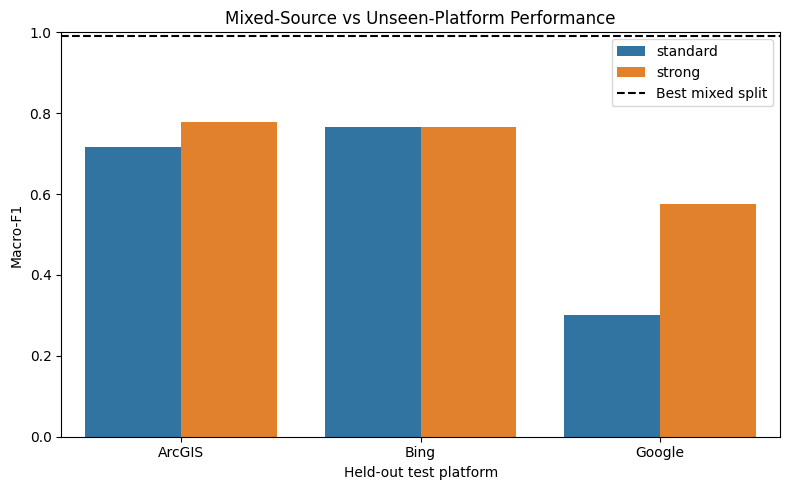

In [28]:
# Cell 26: Poster-ready comparison chart
plot_df = heldout_all[["heldout_source", "augmentation", "macro_f1"]].copy()

plt.figure(figsize=(8, 5))
sns.barplot(data=plot_df, x="heldout_source", y="macro_f1", hue="augmentation")
plt.axhline(mixed_best["macro_f1"], color="black", linestyle="--", label="Best mixed split")
plt.ylim(0, 1)
plt.ylabel("Macro-F1")
plt.xlabel("Held-out test platform")
plt.title("Mixed-Source vs Unseen-Platform Performance")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "platform_generalization_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

In [29]:
# Cell 27: Load a saved model for Grad-CAM (unwrap DataParallel)
EXPERIMENT_TO_EXPLAIN = f"heldout_{summary['hardest_source_standard']}_standard_{BEST_MODEL}"
CHECKPOINT_PATH = OUTPUT_DIR / EXPERIMENT_TO_EXPLAIN / "best_model.pth"
PREDICTIONS_PATH = OUTPUT_DIR / EXPERIMENT_TO_EXPLAIN / "predictions.csv"

xai_model = build_model(BEST_MODEL, len(CLASS_NAMES))
state = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
base_model(xai_model).load_state_dict(state)
# Unwrap if DataParallel for Captum compatibility
if isinstance(xai_model, nn.DataParallel):
    xai_model = xai_model.module
xai_model.eval()

predictions_df = pd.read_csv(PREDICTIONS_PATH)
print(EXPERIMENT_TO_EXPLAIN)
display(predictions_df.head())

heldout_Google_standard_resnet50


,path,source,true_idx,pred_idx,true_label,pred_label,confidence,correct,prob_Agricultural Land,prob_Beaches/Coastline,prob_Built-up Areas,prob_Grasslands/Open Land,prob_Hills/Mountains,prob_Trees/Forests,prob_Water Bodies
0,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,5,2,Trees/Forests,Built-up Areas,0.997935,False,0.000093,0.000571,0.997935,0.000038,0.000045,0.000684,0.000635
1,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,5,2,Trees/Forests,Built-up Areas,0.982596,False,0.000617,0.002493,0.982596,0.000466,0.000627,0.011702,0.001499
2,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,5,2,Trees/Forests,Built-up Areas,0.998771,False,0.000090,0.000578,0.998771,0.000101,0.000056,0.000244,0.000160
3,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,5,2,Trees/Forests,Built-up Areas,0.525970,False,0.033822,0.023565,0.525970,0.055572,0.060826,0.237885,0.062360
4,/kaggle/input/datasets/alifziad/mlc-bd/MLC-BD ...,Google,5,2,Trees/Forests,Built-up Areas,0.706527,False,0.018356,0.006981,0.706527,0.004989,0.010147,0.238746,0.014254


In [30]:
# Cell 28: Grad-CAM helper
def denormalize(tensor):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (tensor.cpu() * std + mean).clamp(0, 1)

def get_target_layer(model_name, model):
    core = base_model(model)
    if model_name == "resnet50":
        return core.layer4[-1].conv3
    if model_name == "mobilenet_v3_large":
        return core.features[-1]
    raise ValueError(model_name)

def make_gradcam(model, model_name, image_path, target_idx=None):
    image = Image.open(image_path).convert("RGB")
    x = eval_transform(image).unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        logits = model(x)
        pred_idx = int(logits.argmax(dim=1).item())
        confidence = float(torch.softmax(logits, dim=1).max().item())

    if target_idx is None:
        target_idx = pred_idx

    target_layer = get_target_layer(model_name, model)
    gradcam = LayerGradCam(model, target_layer)
    attribution = gradcam.attribute(x, target=target_idx)
    attribution = LayerAttribution.interpolate(attribution, (IMG_SIZE, IMG_SIZE))

    heatmap = attribution.squeeze().detach().cpu().numpy()
    heatmap = np.maximum(heatmap, 0)
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    display_img = denormalize(x.squeeze()).permute(1, 2, 0).numpy()
    return display_img, heatmap, pred_idx, confidence

In [32]:
# Cell 29: Select six useful cases
correct_examples = predictions_df[predictions_df.correct == True].copy()
wrong_examples = predictions_df[predictions_df.correct == False].copy()

selected = pd.concat([
    correct_examples.sort_values("confidence", ascending=False).head(3),
    wrong_examples.sort_values("confidence", ascending=False).head(3),
]).reset_index(drop=True)

display(selected[["true_label", "pred_label", "confidence", "correct", "source"]])

,true_label,pred_label,confidence,correct,source
0,Built-up Areas,Built-up Areas,1.000000,True,Google
1,Built-up Areas,Built-up Areas,1.000000,True,Google
2,Built-up Areas,Built-up Areas,0.999999,True,Google
3,Beaches/Coastline,Built-up Areas,0.999987,False,Google
4,Water Bodies,Built-up Areas,0.999985,False,Google
5,Water Bodies,Built-up Areas,0.999983,False,Google


In [33]:
# Cell 30: Generate Grad-CAM panel
fig, axes = plt.subplots(len(selected), 2, figsize=(9, 4 * len(selected)))

for i, row in selected.iterrows():
    display_img, heatmap, pred_idx, confidence = make_gradcam(
        xai_model,
        BEST_MODEL,
        row.path,
        target_idx=int(row.pred_idx)
    )

    axes[i, 0].imshow(display_img)
    axes[i, 0].axis("off")
    axes[i, 0].set_title(
        f"Original | True: {row.true_label}\nPred: {row.pred_label} ({confidence:.2f})"
    )

    axes[i, 1].imshow(display_img)
    axes[i, 1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[i, 1].axis("off")
    axes[i, 1].set_title("Grad-CAM")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "gradcam_panel.png", dpi=220, bbox_inches="tight")
plt.show()

[Image output removed. It showed basemap imagery from Google, Bing or ArcGIS, which is not redistributed in this repository.]


In [34]:
# Cell 31: Zip all outputs
!cd /kaggle/working && zip -qr mlc_bd_all_outputs.zip outputs
print("Created: /kaggle/working/mlc_bd_all_outputs.zip")

Created: /kaggle/working/mlc_bd_all_outputs.zip
